# Analyses de mobilité et croisement météo, vélos et pollution

**Responsable :** Membre 2 (CityBikes). Ce notebook répond aux cinq questions métier de la Partie 2 et au volet vélos de la Partie 4.

**Données :** Silver CityBikes publiée dans le Data Lake (R2 ou MinIO) et table Gold `city_hourly`. En ligne, tout est relu depuis R2 : le Silver local de cette machine n'est jamais utilisé.

**Limite de lecture :** CityBikes fournit des **stocks observés** (vélos disponibles, places libres), pas des trajets. Les indicateurs d'usage sont donc indirects : une variation de stock entre deux relevés signale une activité, sans la mesurer. Chaque résultat affiche le nombre de relevés sur lequel il repose ; les sections qui demandent plus de données l'indiquent au lieu de conclure.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "config" / "cities.yml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.citybikes_stream import build_minio_client, read_silver_remote, read_gold_remote

STORAGE_MODE = "minio"          # "minio" : Silver et Gold relus depuis R2/MinIO ; "local" : dossier data/
MIN_OBS = 10                    # relevés valides minimum par station pour la règle des stations critiques
SEUIL_CRITIQUE = 0.30           # part des relevés vide ou pleine au-delà de laquelle une station est critique
GRILLE_DEG = 0.01               # taille d'une cellule de comparaison géographique (environ 1 km)
FUSEAU = "Europe/Paris"         # heures locales affichées dans les profils journaliers

cities = {c["id"]: c for c in yaml.safe_load((PROJECT_ROOT / "config" / "cities.yml").read_text(encoding="utf-8"))["cities"]}
client, buckets = build_minio_client() if STORAGE_MODE == "minio" else (None, None)
print("Mode :", STORAGE_MODE, "| villes :", list(cities))

Mode : minio | villes : ['paris', 'lyon', 'lille']


## 1. Chargement et couverture

La clé de déduplication est `(network_id, station_id, snapshot_minute_utc)`. Les relevés successifs d'une même station sont conservés même si le stock n'a pas changé.

In [2]:
if STORAGE_MODE == "minio":
    silver = read_silver_remote(client, buckets["silver"])
else:
    from scripts.citybikes_stream import read_silver
    silver = read_silver(PROJECT_ROOT / "data")

if silver.empty:
    raise RuntimeError("Aucun Silver CityBikes disponible : lancer la collecte (scripts/citybikes_stream.py).")

silver = silver.drop_duplicates(["network_id", "station_id", "snapshot_minute_utc"], keep="last").copy()
silver["observed_at_utc"] = pd.to_datetime(silver["observed_at_utc"], utc=True)
silver["bikes_available"] = pd.to_numeric(silver["bikes_available"], errors="coerce")
silver["free_slots"] = pd.to_numeric(silver["free_slots"], errors="coerce")
silver["capacite"] = silver["bikes_available"] + silver["free_slots"]
silver["taux_remplissage"] = silver["bikes_available"] / silver["capacite"].where(silver["capacite"] > 0)
silver["cle"] = silver["network_id"] + "|" + silver["station_id"]

couverture = silver.groupby("city_name").agg(
    stations=("cle", "nunique"),
    releves=("cle", "size"),
    cycles=("observed_at_utc", "nunique"),
    premier=("observed_at_utc", "min"),
    dernier=("observed_at_utc", "max"),
)
couverture["duree_h"] = ((couverture["dernier"] - couverture["premier"]).dt.total_seconds() / 3600).round(1)
display(couverture)

duree_totale_h = (silver["observed_at_utc"].max() - silver["observed_at_utc"].min()).total_seconds() / 3600
n_cycles = silver["observed_at_utc"].nunique()
print(f"Période observée : {duree_totale_h:.1f} h, {n_cycles} instants de collecte distincts.")
if duree_totale_h < 24:
    print("[ATTENTION] Moins de 24 h de collecte : les profils journaliers et les stations critiques ne sont pas encore fiables. "
          "Laisser tourner la collecte (toutes les 5 minutes) puis relancer ce notebook.")

,stations,releves,cycles,premier,dernier,duree_h
city_name,,,,,,
Lille,267,534,2,2026-11-19 11:09:47.803570+00:00,2026-11-19 11:39:33.216598+00:00,0.5
Lyon,458,916,2,2026-11-19 11:09:46.241326+00:00,2026-11-19 11:39:31.688990+00:00,0.5
Paris,1522,3044,2,2026-11-19 11:09:44.416627+00:00,2026-11-19 11:39:29.822460+00:00,0.5


Période observée : 0.5 h, 6 instants de collecte distincts.
[ATTENTION] Moins de 24 h de collecte : les profils journaliers et les stations critiques ne sont pas encore fiables. Laisser tourner la collecte (toutes les 5 minutes) puis relancer ce notebook.


## 2. Question 1 : quelles stations présentent le plus fort taux d'utilisation ?

Indicateur indirect : l'**activité** d'une station est la somme des variations absolues de son stock entre deux relevés successifs, rapportée à sa capacité et au nombre d'intervalles. Une station très active se vide et se remplit souvent.

In [3]:
silver = silver.sort_values(["cle", "observed_at_utc"])
silver["variation"] = silver.groupby("cle")["bikes_available"].diff().abs()
par_station = silver.groupby("cle").agg(
    ville=("city_name", "first"), station=("station_name", "first"),
    capacite=("capacite", "median"), releves=("bikes_available", "count"),
    variation_totale=("variation", "sum"), intervalles=("variation", "count"),
).reset_index()
par_station = par_station[(par_station["intervalles"] >= 1) & (par_station["capacite"] > 0)].copy()
par_station["activite"] = par_station["variation_totale"] / par_station["capacite"] / par_station["intervalles"]

if par_station.empty:
    print("[ATTENTION] Il faut au moins deux relevés par station.")
else:
    print(f"Activité calculée sur {len(par_station)} stations, avec {int(par_station['intervalles'].median())} intervalle(s) par station en médiane.")
    for ville, g in par_station.groupby("ville"):
        print(f"\nTop 10 des stations les plus actives : {ville}")
        display(g.nlargest(10, "activite")[["station", "capacite", "releves", "variation_totale", "activite"]].round(3).reset_index(drop=True))

Activité calculée sur 2239 stations, avec 1 intervalle(s) par station en médiane.

Top 10 des stations les plus actives : Lille


,station,capacite,releves,variation_totale,activite
0,Molinel,22.0,2,8,0.364
1,Rue du Parc,12.0,2,4,0.333
2,Solferino Nationale,19.0,2,5,0.263
3,Boulevard Louis XIV,26.0,2,6,0.231
4,Angellier,26.0,2,6,0.231
5,Hotel de Region,30.0,2,6,0.2
6,Trevise,20.0,2,4,0.2
7,Universite Catholique,31.0,2,6,0.194
8,Rue Bonte-Pollet,16.0,2,3,0.188
9,Campus St Raphael,16.0,2,3,0.188



Top 10 des stations les plus actives : Lyon


,station,capacite,releves,variation_totale,activite
0,10025 - TOTEM,14.0,2,13,0.929
1,TRONCHET / ANATOLE FRANCE,10.0,2,9,0.9
2,IUT / FEYSSINE,29.0,2,18,0.621
3,LONGEFER / KRUGER,15.0,2,9,0.6
4,LAFAYETTE / CORNEILLE,7.0,2,4,0.571
5,PLACE BERTONE,9.5,2,5,0.526
6,GARIBALDI,10.5,2,5,0.476
7,TERREAUX / BEAUX ARTS,8.5,2,4,0.471
8,PERRACHE / CARNOT,15.5,2,7,0.452
9,7010 - CENTRE BERTHELOT,15.5,2,7,0.452



Top 10 des stations les plus actives : Paris


,station,capacite,releves,variation_totale,activite
0,Quai des Célestins - Henri IV,9.5,2,5,0.526
1,Chabrol - d'Hauteville,10.0,2,5,0.5
2,Cité Riverin - Château d'Eau,15.0,2,7,0.467
3,Victor Cousin - Cujas,19.0,2,7,0.368
4,Billancourt - Général Leclerc,22.0,2,8,0.364
5,Jules Guesde - Alsace,22.0,2,8,0.364
6,Jean-Baptiste Pigalle - La Bruyere,17.0,2,6,0.353
7,Charenton - Place du Col Bourgoin,35.0,2,12,0.343
8,Marché Saint-Quentin,15.0,2,5,0.333
9,Michelet - Assas,18.0,2,5,0.278


## 3. Questions 2 et 4 : zones à offre insuffisante et déséquilibres géographiques

Le taux de remplissage d'une station est `vélos / (vélos + places libres)`. Les stations sont regroupées dans des cellules d'environ 1 km. Une cellule est signalée à partir de 3 stations pour éviter les conclusions sur un point isolé. La distance au centre-ville mesure l'écart entre centre et périphérie.

614 cellules, dont 271 avec au moins 3 stations.

Zones à l'offre la plus faible (remplissage moyen le plus bas) : lille


,cellule,stations,remplissage,vide,lat,lon
0,5067_317,3,0.042,0.667,50.677,3.175
1,5071_316,4,0.125,0.25,50.717,3.165
2,5067_316,3,0.133,0.667,50.676,3.164
3,5071_315,4,0.156,0.0,50.716,3.158
4,5069_316,5,0.156,0.6,50.694,3.166



Zones à l'offre la plus faible (remplissage moyen le plus bas) : lyon


,cellule,stations,remplissage,vide,lat,lon
0,4575_478,4,0.0,1.0,45.753,4.786
1,4575_480,3,0.0,1.0,45.755,4.805
2,4575_481,4,0.007,0.875,45.757,4.815
3,4576_480,3,0.009,0.833,45.766,4.806
4,4573_488,4,0.073,0.375,45.735,4.887



Zones à l'offre la plus faible (remplissage moyen le plus bas) : paris


,cellule,stations,remplissage,vide,lat,lon
0,4880_228,3,0.006,0.833,48.805,2.286
1,4887_239,8,0.009,0.875,48.874,2.396
2,4887_240,7,0.009,0.786,48.874,2.405
3,4887_242,3,0.025,0.5,48.873,2.425
4,4886_239,7,0.026,0.571,48.866,2.395


Lille : remplissage et distance au centre, rho = -0.21 sur 266 stations (p = 4.4e-04).
Lyon : remplissage et distance au centre, rho = +0.08 sur 456 stations (p = 7.7e-02).
Paris : remplissage et distance au centre, rho = -0.10 sur 1517 stations (p = 1.1e-04).


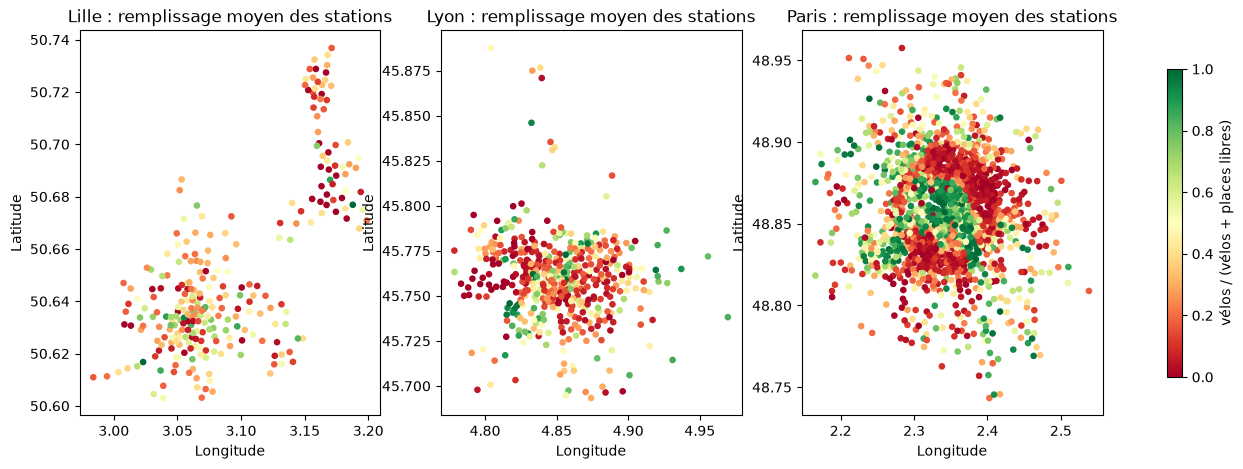

In [4]:
def distance_km(lat, lon, lat0, lon0):
    r = 6371.0
    p1, p2 = np.radians(lat), np.radians(lat0)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon0 - lon) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

stations = silver.groupby("cle").agg(
    ville=("city_id", "first"), nom=("station_name", "first"), lat=("latitude", "first"), lon=("longitude", "first"),
    remplissage=("taux_remplissage", "mean"), releves=("taux_remplissage", "count"),
    vide=("bikes_available", lambda s: float((s.dropna() == 0).mean())),
    pleine=("free_slots", lambda s: float((s.dropna() == 0).mean())),
).dropna(subset=["lat", "lon", "remplissage"]).reset_index()
stations["dist_centre_km"] = [distance_km(r.lat, r.lon, cities[r.ville]["latitude"], cities[r.ville]["longitude"]) for r in stations.itertuples()]
stations["cellule"] = (np.floor(stations["lat"] / GRILLE_DEG).astype(int).astype(str) + "_" + np.floor(stations["lon"] / GRILLE_DEG).astype(int).astype(str))

cellules = stations.groupby(["ville", "cellule"]).agg(
    stations=("cle", "size"), remplissage=("remplissage", "mean"), vide=("vide", "mean"),
    lat=("lat", "mean"), lon=("lon", "mean"),
).reset_index()
fiables = cellules[cellules["stations"] >= 3]
print(f"{len(cellules)} cellules, dont {len(fiables)} avec au moins 3 stations.")
for ville, g in fiables.groupby("ville"):
    print(f"\nZones à l'offre la plus faible (remplissage moyen le plus bas) : {ville}")
    display(g.nsmallest(5, "remplissage")[["cellule", "stations", "remplissage", "vide", "lat", "lon"]].round(3).reset_index(drop=True))

# Déséquilibre centre / périphérie
for ville, g in stations.groupby("ville"):
    if len(g) >= 30 and g["dist_centre_km"].nunique() > 1:
        rho, p = stats.spearmanr(g["dist_centre_km"], g["remplissage"])
        print(f"{cities[ville]['name']} : remplissage et distance au centre, rho = {rho:+.2f} sur {len(g)} stations (p = {p:.1e}).")

fig, axes = plt.subplots(1, len(stations["ville"].unique()), figsize=(5.5 * len(stations["ville"].unique()), 5))
axes = np.atleast_1d(axes)
for ax, (ville, g) in zip(axes, stations.groupby("ville")):
    sc = ax.scatter(g["lon"], g["lat"], c=g["remplissage"], cmap="RdYlGn", vmin=0, vmax=1, s=14)
    ax.set_title(f"{cities[ville]['name']} : remplissage moyen des stations")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.colorbar(sc, ax=axes.tolist(), label="vélos / (vélos + places libres)", shrink=0.8)
plt.show()

## 4. Question 3 : pics d'utilisation journaliers

Profil par **heure locale** du remplissage moyen et de l'activité. Il n'est lisible que si la collecte couvre plusieurs jours ; le nombre d'heures du jour réellement observées est affiché.

In [5]:
silver["heure_locale"] = silver["observed_at_utc"].dt.tz_convert(FUSEAU).dt.hour
profil = silver.groupby("heure_locale").agg(
    remplissage=("taux_remplissage", "mean"), activite=("variation", "mean"), releves=("cle", "size"),
).reindex(range(24))
observees = int(profil["releves"].notna().sum())
print(f"Heures du jour observées : {observees} sur 24.")
if observees < 12:
    print("[ATTENTION] La collecte ne couvre pas assez d'heures du jour pour identifier des pics. Relancer après plusieurs jours de collecte.")
else:
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(profil.index, profil["remplissage"], marker="o", color="#2980b9", label="Remplissage moyen")
    ax.set_xlabel("Heure locale"); ax.set_ylabel("Remplissage moyen"); ax.set_xticks(range(24))
    ax2 = ax.twinx(); ax2.bar(profil.index, profil["activite"], alpha=0.25, color="#e67e22", label="Activité moyenne (vélos)")
    ax2.set_ylabel("Variation moyenne du stock par relevé")
    ax.set_title("Profil journalier du réseau (heure locale)")
    plt.show()
    pics = profil["activite"].nlargest(3)
    print("Heures les plus actives :", {int(h): round(float(v), 2) for h, v in pics.items()}, "(sur la période observée seulement)")
display(profil.dropna().round(3))

Heures du jour observées : 1 sur 24.
[ATTENTION] La collecte ne couvre pas assez d'heures du jour pour identifier des pics. Relancer après plusieurs jours de collecte.


,remplissage,activite,releves
heure_locale,,,
12,0.377,1.399,4494.0


## 5. Question 5 : stations critiques nécessitant un rééquilibrage

Règle réglable : une station est **critique** si elle est vide ou pleine dans au moins `SEUIL_CRITIQUE` (30 %) de ses relevés valides, avec au moins `MIN_OBS` relevés. Tant que la collecte est courte, la règle est appliquée à titre provisoire avec le minimum de relevés disponible.

In [6]:
releves_max = int(stations["releves"].max()) if not stations.empty else 0
min_obs_effectif = MIN_OBS if releves_max >= MIN_OBS else max(2, releves_max)
if min_obs_effectif < MIN_OBS:
    print(f"[ATTENTION] Résultat provisoire : {releves_max} relevé(s) par station au maximum, règle appliquée avec {min_obs_effectif} au lieu de {MIN_OBS}.")
candidats = stations[stations["releves"] >= min_obs_effectif].copy()
candidats["critique_vide"] = candidats["vide"] >= SEUIL_CRITIQUE
candidats["critique_pleine"] = candidats["pleine"] >= SEUIL_CRITIQUE
critiques = candidats[candidats["critique_vide"] | candidats["critique_pleine"]]
print(f"Stations critiques : {len(critiques)} sur {len(candidats)} évaluées.")
resume = critiques.groupby("ville").agg(vides=("critique_vide", "sum"), pleines=("critique_pleine", "sum"), total=("cle", "size"))
display(resume)
display(critiques.sort_values(["vide", "pleine"], ascending=False)[["ville", "nom", "releves", "vide", "pleine", "dist_centre_km"]].head(15).round(2).reset_index(drop=True))

[ATTENTION] Résultat provisoire : 2 relevé(s) par station au maximum, règle appliquée avec 2 au lieu de 10.
Stations critiques : 472 sur 2239 évaluées.


,vides,pleines,total
ville,,,
lille,37,3,40
lyon,113,15,128
paris,209,95,304


,ville,nom,releves,vide,pleine,dist_centre_km
0,paris,Belleville - Télégraphe,2,1.0,0.0,4.06
1,paris,Bons Raisins - Voltaire,2,1.0,0.0,11.66
2,paris,Plantes - Moulin Vert,2,1.0,0.0,3.63
3,paris,Marcelle - Thalie,2,1.0,0.0,5.41
4,paris,Place de la Bastille - Bourdon,2,1.0,0.0,1.26
5,paris,Gare de Chaville Rive Gauche,2,1.0,0.0,13.29
6,paris,Colonel Fabien - Sallnave,2,1.0,0.0,6.15
7,paris,Division Leclerc - Kléber,2,1.0,0.0,8.18
8,paris,Borrégo - Gambetta,2,1.0,0.0,4.05
9,paris,Gare du Stade,2,1.0,0.0,10.68


## 6. Croisement météo et vélos (Partie 4)

La table `city_hourly` contient, par ville et par heure UTC, le stock de vélos agrégé et la météo. L'analyse n'est lancée que si au moins 24 heures communes existent ; sinon le notebook affiche le diagnostic de couverture.

In [7]:
if STORAGE_MODE == "minio":
    import io
    resp = client.get_object(buckets["gold"], "kpis/city_hourly.parquet")
    ch = pd.read_parquet(io.BytesIO(resp.read())); resp.close(); resp.release_conn()
else:
    ch = pd.DataFrame()

if ch.empty:
    print("[ATTENTION] city_hourly indisponible : lancer le notebook 03.")
else:
    ch["hour_utc"] = pd.to_datetime(ch["hour_utc"], utc=True)
    print("Statuts de jointure :", ch["statut_jointure"].value_counts().to_dict())
    velos = ch.dropna(subset=["mobility_bikes_available", "weather_temperature_c"]).copy()
    velos["remplissage"] = velos["mobility_bikes_available"] / (velos["mobility_bikes_available"] + velos["mobility_free_slots"])
    print(f"Heures vélos et météo communes : {len(velos)}")
    if len(velos) < 24:
        print("[ATTENTION] Moins de 24 heures communes : aucune corrélation n'est calculée, elle ne serait pas défendable. "
              "Elle sera disponible après quelques jours de collecte CityBikes.")
    else:
        lignes = []
        for col, label in (("weather_precipitation_mm", "Pluie"), ("weather_temperature_c", "Température"),
                           ("weather_wind_speed_ms", "Vent")):
            sub = velos[["remplissage", col]].dropna()
            if len(sub) >= 24 and sub[col].nunique() > 1:
                rho, p = stats.spearmanr(sub[col], sub["remplissage"])
                lignes.append({"Météo": label, "rho": round(rho, 2), "p": f"{p:.1e}", "heures": len(sub)})
        display(pd.DataFrame(lignes))
        pluie = velos[velos["weather_precipitation_mm"] > 0]["remplissage"]; sec = velos[velos["weather_precipitation_mm"] <= 0]["remplissage"]
        if len(pluie) >= 5 and len(sec) >= 5:
            print(f"Remplissage médian : {pluie.median():.2f} avec pluie ({len(pluie)} h), {sec.median():.2f} sans pluie ({len(sec)} h).")
    triple = ch[ch["statut_jointure"].eq("complete_3_sources")]
    print(f"Heures où mobilité, pollution et météo coexistent : {len(triple)}")

Statuts de jointure : {'meteo_seule': 180080, 'pollution_et_meteo': 967, 'complete_3_sources': 3}
Heures vélos et météo communes : 3
[ATTENTION] Moins de 24 heures communes : aucune corrélation n'est calculée, elle ne serait pas défendable. Elle sera disponible après quelques jours de collecte CityBikes.
Heures où mobilité, pollution et météo coexistent : 3


## 7. Synthèse et limites

- La collecte CityBikes tourne toutes les 5 minutes ; les résultats de ce notebook gagnent en fiabilité à mesure que la période s'allonge. Les messages `[ATTENTION]` indiquent les sections qui attendent encore des données.
- Les indicateurs d'usage reposent sur des variations de stock : ils signalent l'activité d'une station sans compter les trajets.
- Les conditions favorables à la mobilité douce se lisent dans la section 6 : une corrélation entre la pluie, la température et le remplissage n'est publiée qu'à partir de 24 heures communes.
- Relancer ce notebook après plusieurs jours de collecte, puis recopier les conclusions chiffrées dans les documents de rendu.